# 矩形翼与曲面翼：升力和三轴载荷验证

单翼、保留两侧传动，羽化限位 ±26.1°。矩形翼膜 80 × 26 mm，独立模型。
本 Notebook 从已保存仿真和原始实测重新计算比较；不隐藏物理仿真运行。
完整重跑命令见下方报告。质量、膜边界和实测尾段基线尚有未确认假设。
方向拟合固定 Z，仅允许 yaw；10–12 Hz 拟合，13–15 Hz 留出。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
from IPython.display import display, Image, Markdown
here = Path.cwd().resolve()
ROOT = next(p for p in (here,*here.parents) if (p/'flapsim/simulator.py').is_file())
FOLDER = ROOT/'experiments/fixbase_curved_real'
sys.path.insert(0,str(FOLDER))
from rect_compare import compare
from rect_report import make_report
from rect_simulation import OUTPUT
comparisons, orientation = compare()
report = make_report()
display(Markdown(report.split('## X/Y')[0].replace('![升力](lift_validation.png)','').replace('![几何](geometry_comparison.png)','')))

{
  "lift": [
    {
      "kind": "curve",
      "hz": 10,
      "encoder_hz": 10.121712587062808,
      "simulation_hz": 10.121687494378516,
      "real_lift_mN": 15.218095763231133,
      "real_sd_mN": 0.22244155330432733,
      "sim_lift_mN": 12.657602738848313,
      "relative_error_pct": -16.825318122713483,
      "real_Fx_mN": 1.1166041166537373,
      "sim_Fx_mN": -0.0003067210594372273,
      "fixture_mean_residual_Fx_mN": -0.1574625927481701,
      "mean_inertial_Fx_mN": -1.1263077718579868e-05,
      "real_Fy_mN": 0.23980895022549195,
      "sim_Fy_mN": 1.7681209102225544,
      "fixture_mean_residual_Fy_mN": 0.004756354438718033,
      "mean_inertial_Fy_mN": -2.567249656361808e-06,
      "real_Fz_mN": 15.218095763231133,
      "sim_Fz_mN": 12.657602738848313,
      "fixture_mean_residual_Fz_mN": -0.9987764885903919,
      "mean_inertial_Fz_mN": 6.066260892145112e-17
    },
    {
      "kind": "curve",
      "hz": 11,
      "encoder_hz": 11.136509956411329,
      "simulation_

# 矩形翼与曲面翼：固定基座升力和三轴力验证

## Material Passport
- 模式：实验执行 + 描述性验证；Verification Status: ANALYZED。
- 输入：两类翼各 18 次实测，10–15 Hz、每档 3 次；原始文件保持不变。
- 输出：独立矩形翼模型、12 档仿真、质量/离散化敏感性、方向拟合、CSV 和已执行 Notebook。
- 本报告验证模型与所给记录的差异；不把方向拟合数据作为独立验证，也不宣称气动模型已经通过验证。

## 主要结果
矩形翼平均升力比实测低 **24.5%–28.8%**。
15 Hz 档为 **42.22 mN 仿真 / 59.32 mN 实测**。
曲面翼 15 Hz 档为 27.29 / 29.85 mN，误差 -8.6%。
因此，曲面翼采用 CAD 轮廓后更接近实测，并不意味着同一模型已能准确预测矩形翼。

|档位 Hz|编码器 Hz|仿真 Hz|实测 Fz ± SD / mN|仿真 Fz / mN|相对误差|
|---:|---:|---:|---:|---:|---:|
|10|10.0240|10.0236|25.93 ± 0.42|19.05|-26.5%|
|11|11.1224|11.1216|31.68 ± 0.73|23.40|-26.1%|
|12|12.0228|12.0218|36.16 ± 0.57|27.30|-24.5%|
|13|13.0897|13.0881|44.40 ± 2.09|32.30|-27.2%|
|14|13.9742|13.9718|51.32 ± 0.79|36.75|-28.4%|
|15|14.9920|14.9846|59.32 ± 1.54|42.22|-28.8%|



## 几何和动力学模型
- 单片左翼；两侧扑翼传动保留；羽化限位 ±26.1°；固定基座，电机动力学驱动，无指定扑翼/羽化轨迹。
- 矩形翼使用独立 MJCF，曲面翼 mesh 不会被覆盖。STEP 翼架、可视翼膜、气动面积、质心和惯量均单独构建。
- `Rectangular.STEP` 是翼架，并没有完整翼膜。按用户给定 80 × 26 mm，气动面积为 **20.8 cm²**；曲面翼 CAD 投影面积约 **18.68 cm²**。
- 矩形翼膜暂放在 STEP X=0..80 mm、Y=2..28 mm；body=(STEP Z, STEP X, STEP Y)，再加 (-0.35, 2.25, 4) mm。
  安装偏移来自新旧几何外廓的对应，是待核对假设，并非通过力数据拟合。
- 未收到矩形翼实测质量；暂设膜厚 25 µm，用既有曲面翼质量除以“曲面 STEP 体积 + 膜体积”估计等效均匀密度。
  估计矩形翼质量 **280.9 mg**；这不等同于已知真实材料密度/质量分布。
- 气动系数保持原值：ρ=1.225 kg/m³、chord_drag=0.08、rotational_drag=5；矩形翼按常弦长叶素，曲面翼按 CAD 分条宽度和弦向中心。
  没有根据本次实测调整升力系数、阻力系数或力倍率。



## 平均力口径与数值检查
- 实测：原始 N 单位力记录，0.5–4.0 s 平均，减去 5.5 s 到记录末尾前 0.1 s 的尾段均值；正 Fz 作为升力。
  波形尾段确实安静，但停机/去皮事件尚未由用户确认，结论以该基线假设为条件。两类翼用同一处理流程。
- 三次重复的误差棒是样本 SD，不能当作仿真误差或 95% CI；没有把每个采样点当作独立重复。
- 改用 0.5–3.5 / 1–4 s 运动窗口、5.5 / 6 s 开始尾段时，矩形单次 Fz 估计最大跨度约 1.21 mN，详见 real_runs.csv。
- 仿真：每组 2 s，步长 5 µs，2 kHz 记录；剔除前 0.6 s 后按完整输出轴周期积分。目标是各档实测编码器平均频率，而非强行整数 Hz。
  同一记录中测力周期与编码器平均频率也有差别：本次追踪差值范围 +0.131 到 +0.234 Hz。
  两个记录没有共同时间基准，不能把它们直接逐点拼接；频率/时钟/工况的一致性仍需复核。
- 所有仿真通过有限数、警告、频率和固定基座检查。完整周期气动力均值用于报告升力。
- 直接以 2 kHz 对尖锐支座反力积分出现数 mN 偏差。方向匹配改用 **F_fixture_dynamic = F_aero − dP/dt**：
  记录总线动量 P，再对其 1–4 阶傅里叶系数求导，得到对应频带的惯性反力。
  直接反力仍保存为原始诊断；不能把其未收敛的均值用于升力结论。

|15 Hz 检查项|实际 Hz|平均 Fz / mN|
|---|---:|---:|
|主模型，12 叶素|14.9846|42.215|
|质量、惯量同时 × 0.75|14.9920|41.500|
|质量、惯量同时 × 1.25|14.9916|42.743|
|24 叶素|14.9891|42.282|

质量/惯量同时 ±25% 仅是有界敏感性检查，不覆盖所有膜柔性、安装位置或惯量分布误差；叶素数检查也不等于完整数值收敛证明。



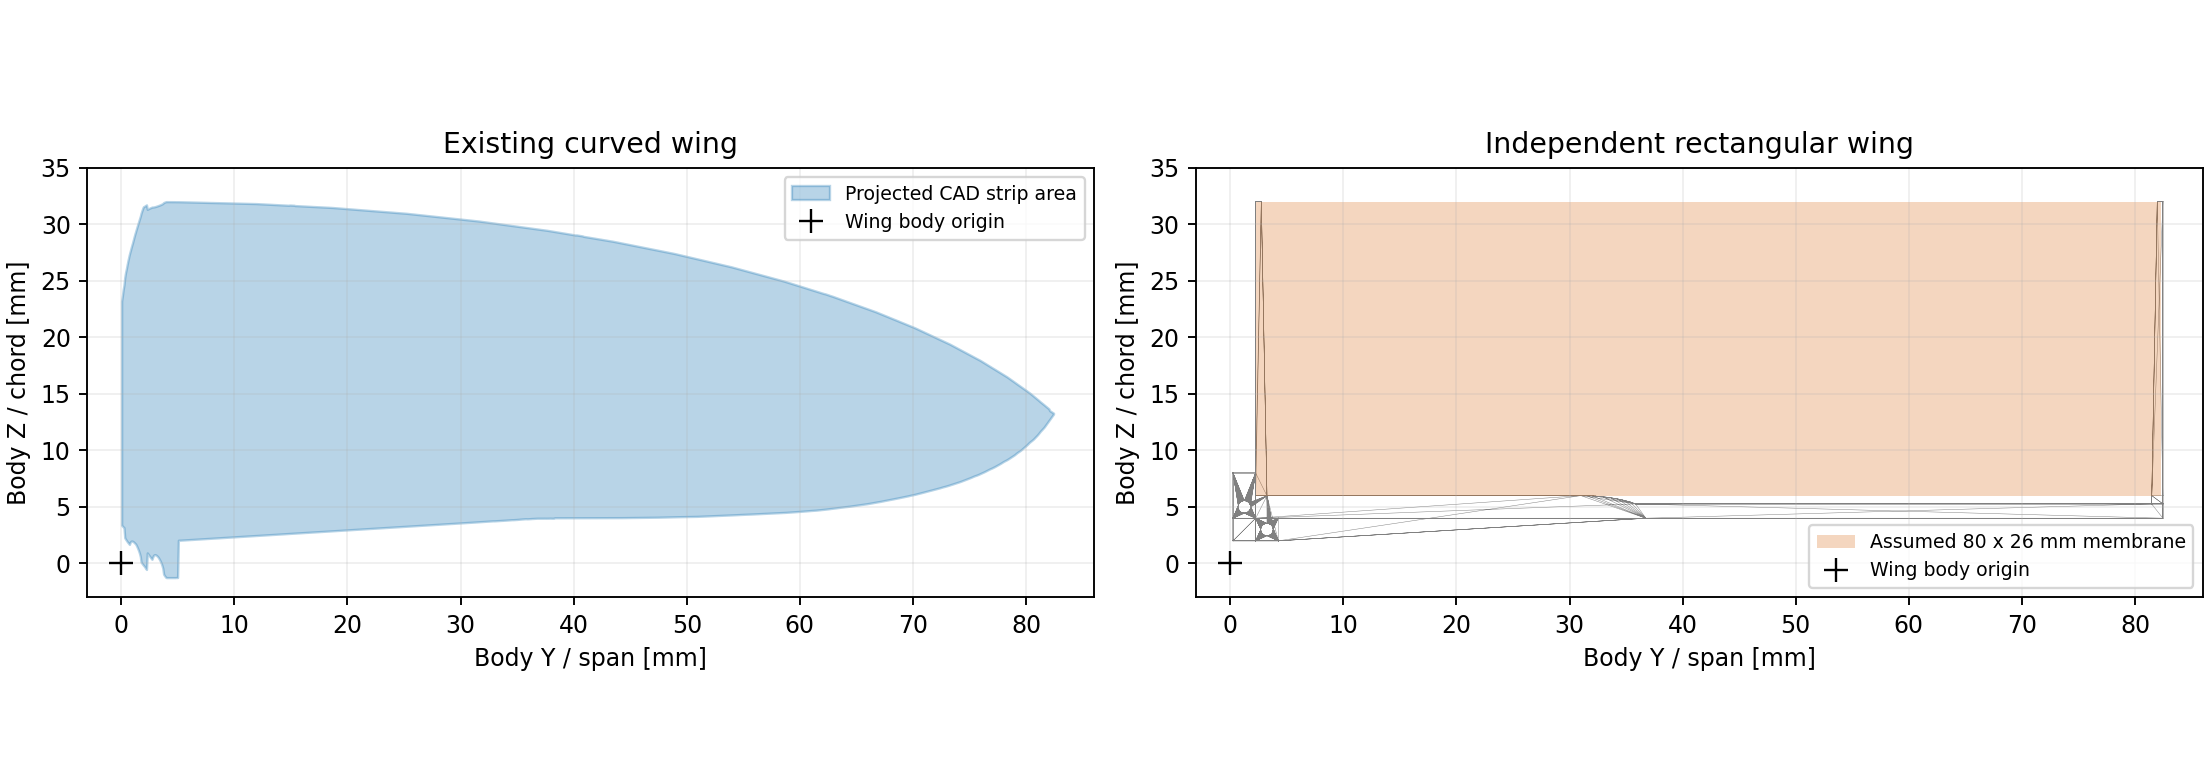

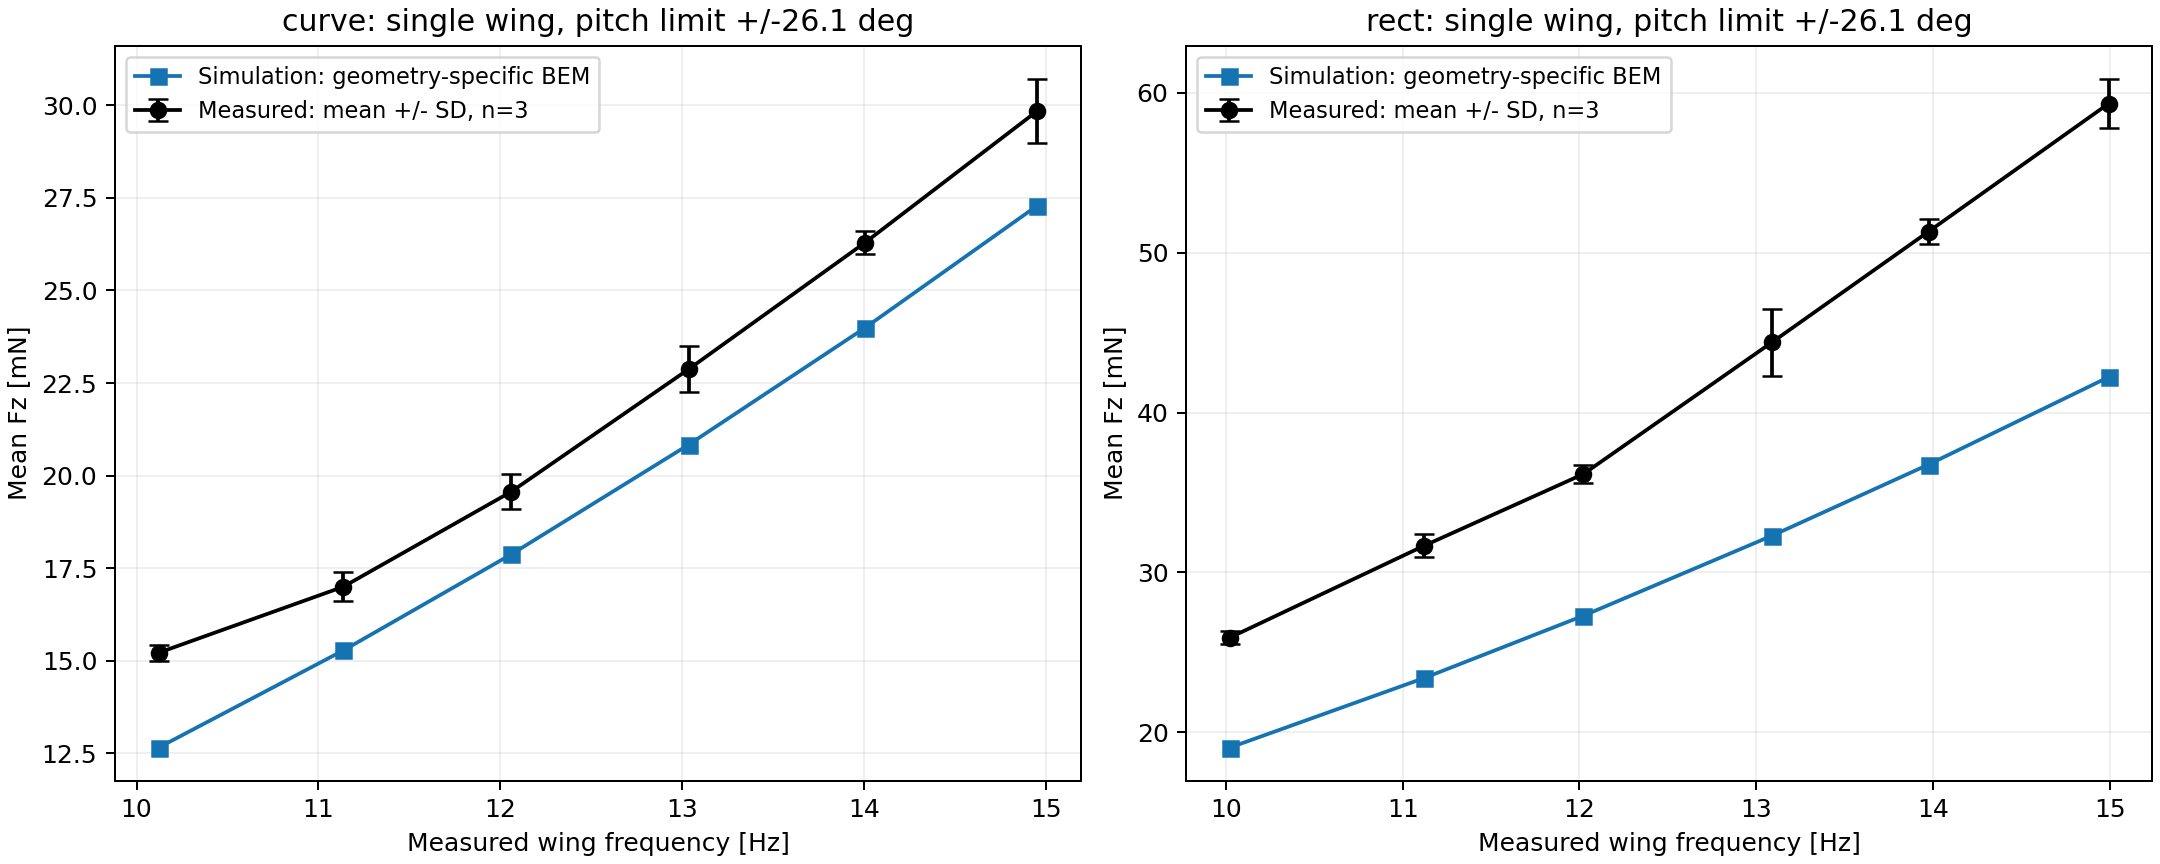

In [2]:
display(Image(filename=str(OUTPUT/'geometry_comparison.png')))
display(Image(filename=str(OUTPUT/'lift_validation.png')))

curve yaw= -27.5 deg; held-out XY NRMSE= 0.582
rect yaw= -31.5 deg; held-out XY NRMSE= 0.558
shared yaw= -29.5 deg; held-out XY NRMSE= 0.568


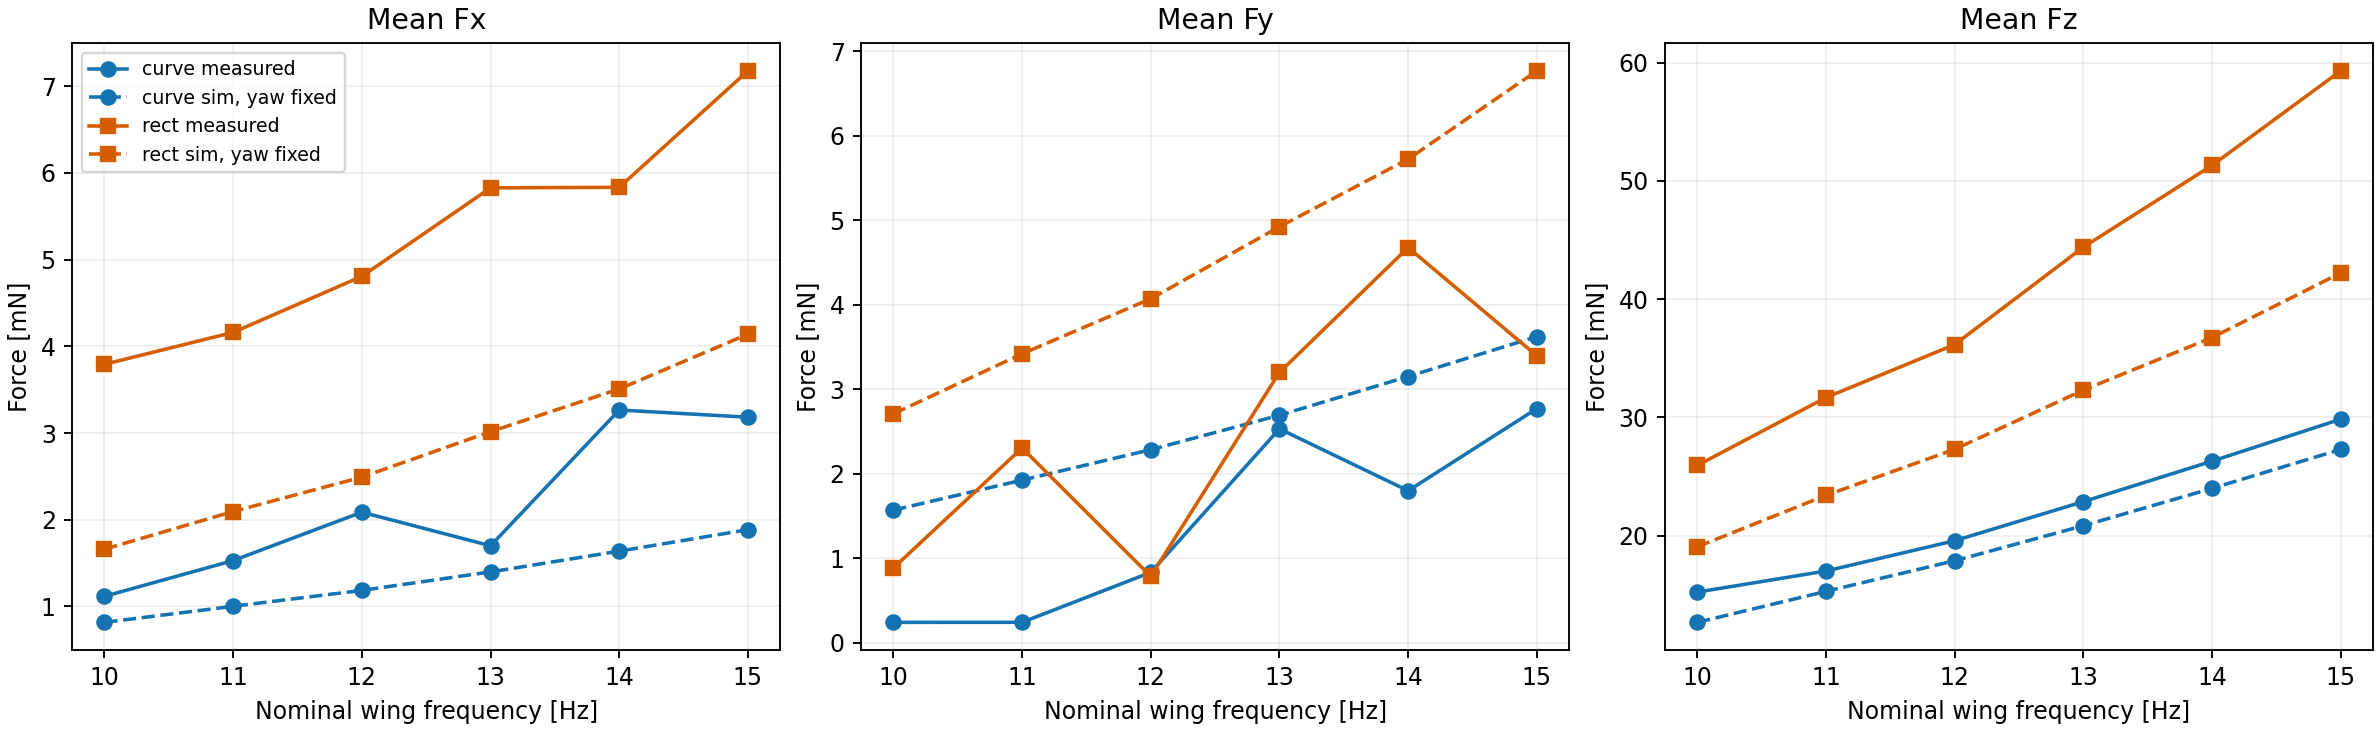

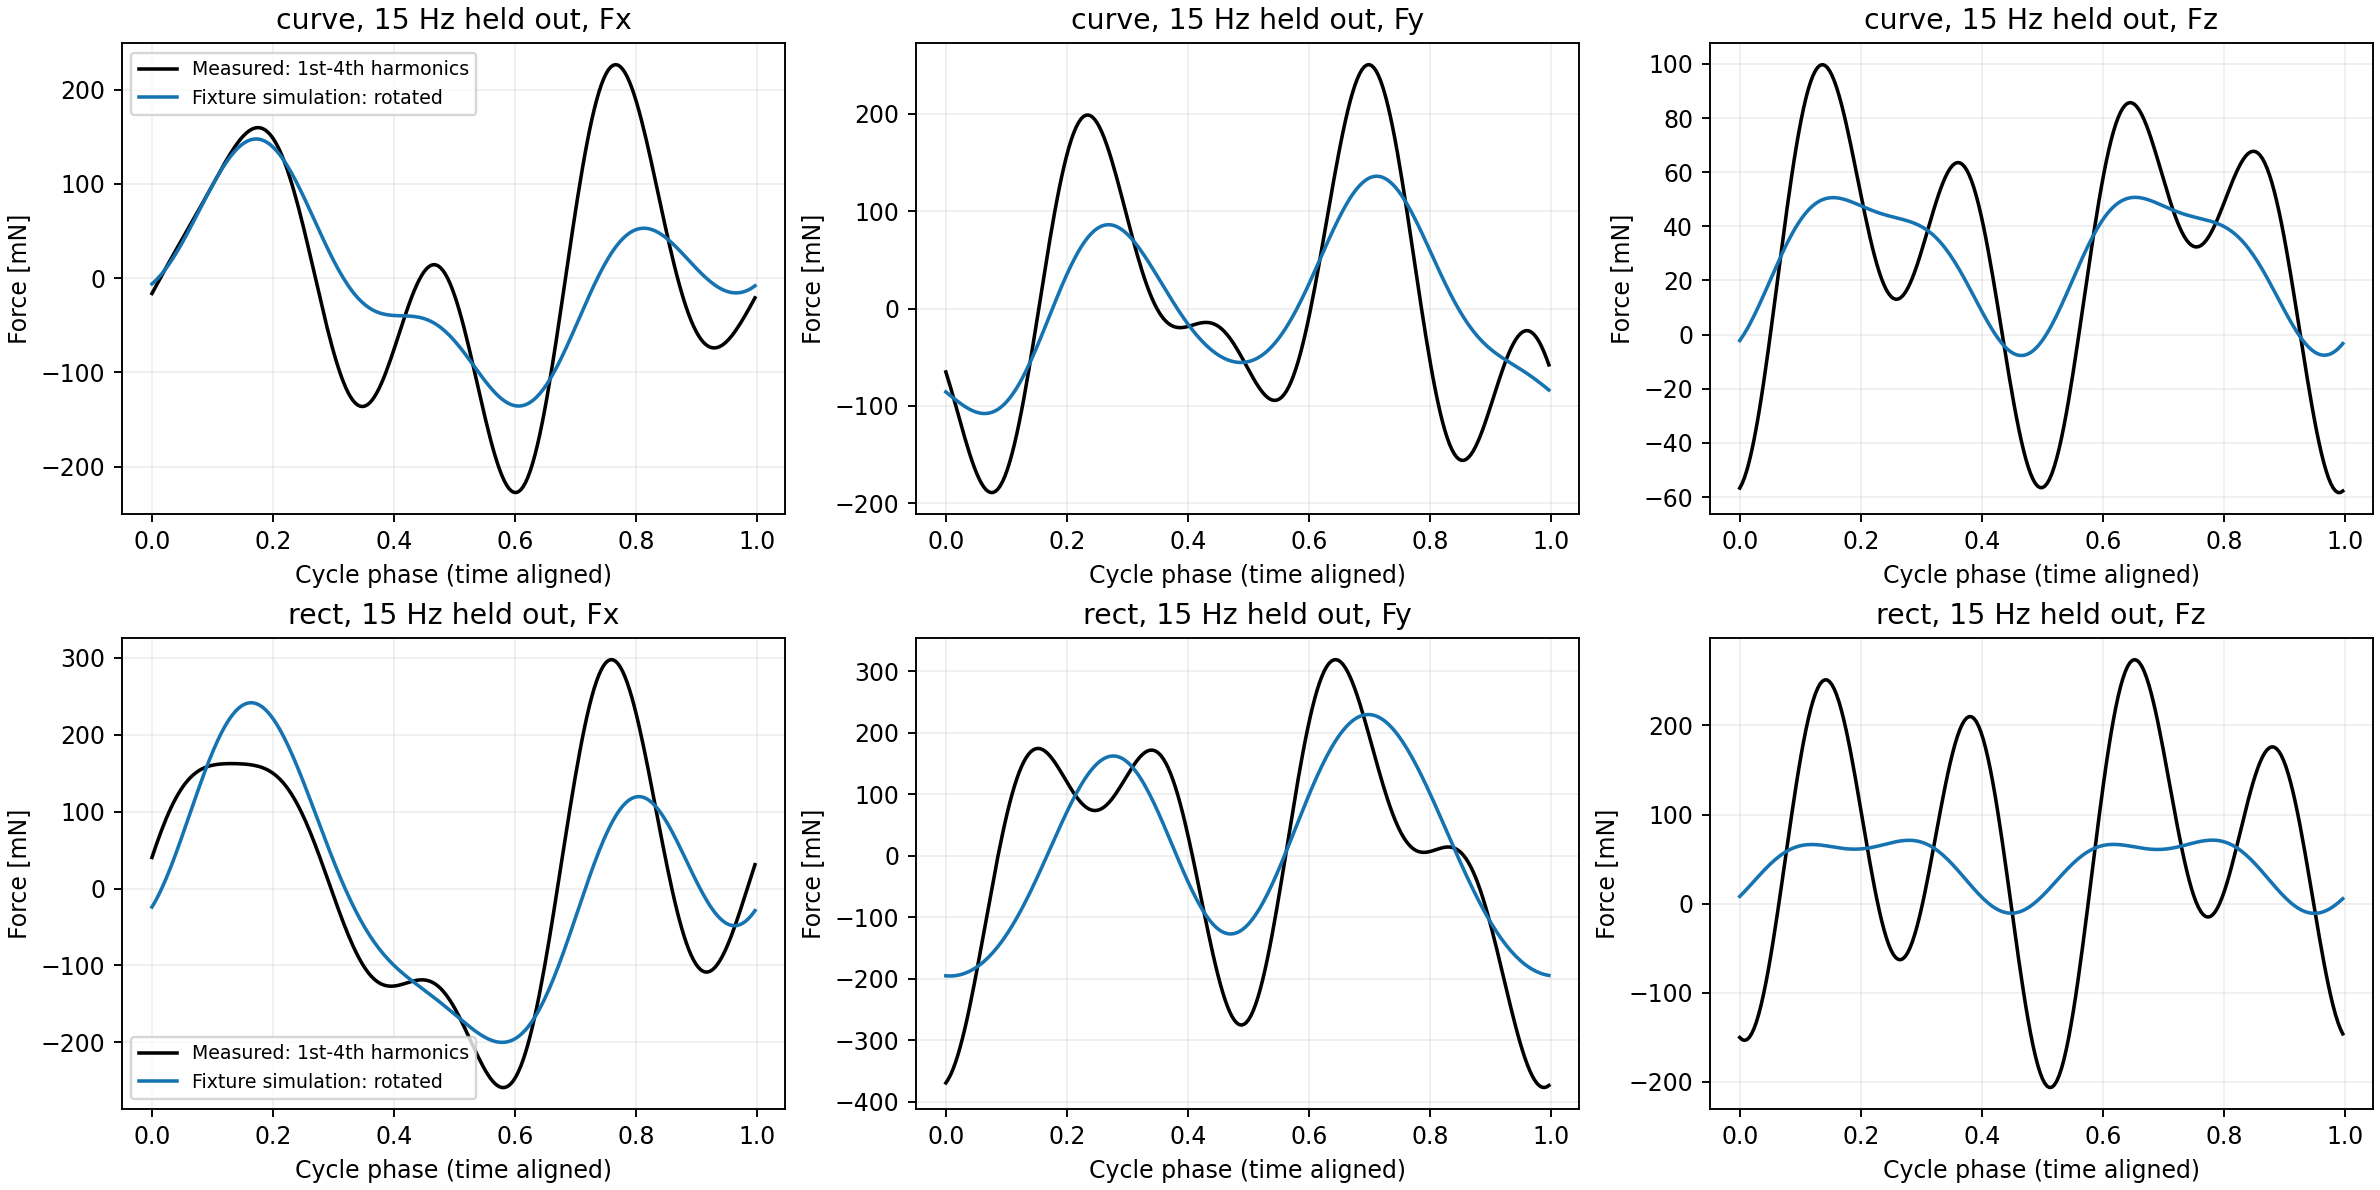

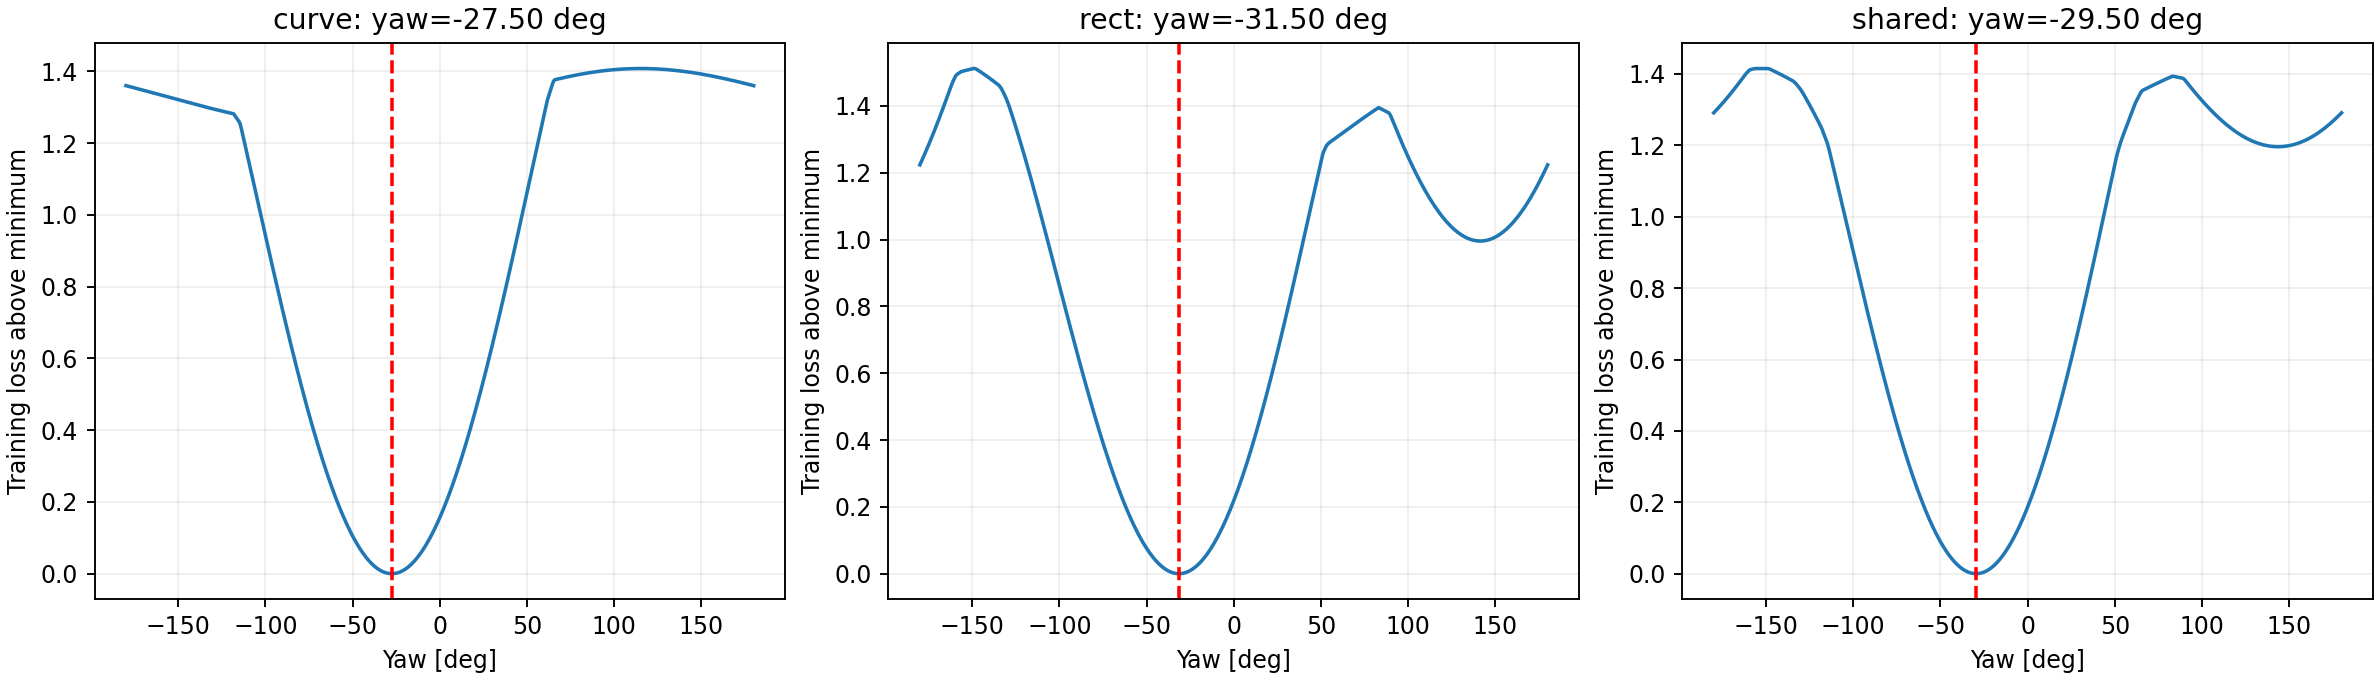

In [3]:
for key in ('curve','rect','shared'):
    f=orientation[key]
    print(key, 'yaw=', round(f['yaw_deg'],2), 'deg; held-out XY NRMSE=', round(f['test_xy_nrmse_mean'],3))
display(Image(filename=str(OUTPUT/'mean_force_xyz.png')))
display(Image(filename=str(OUTPUT/'force_waveform_validation.png')))
display(Image(filename=str(OUTPUT/'yaw_identification.png')))

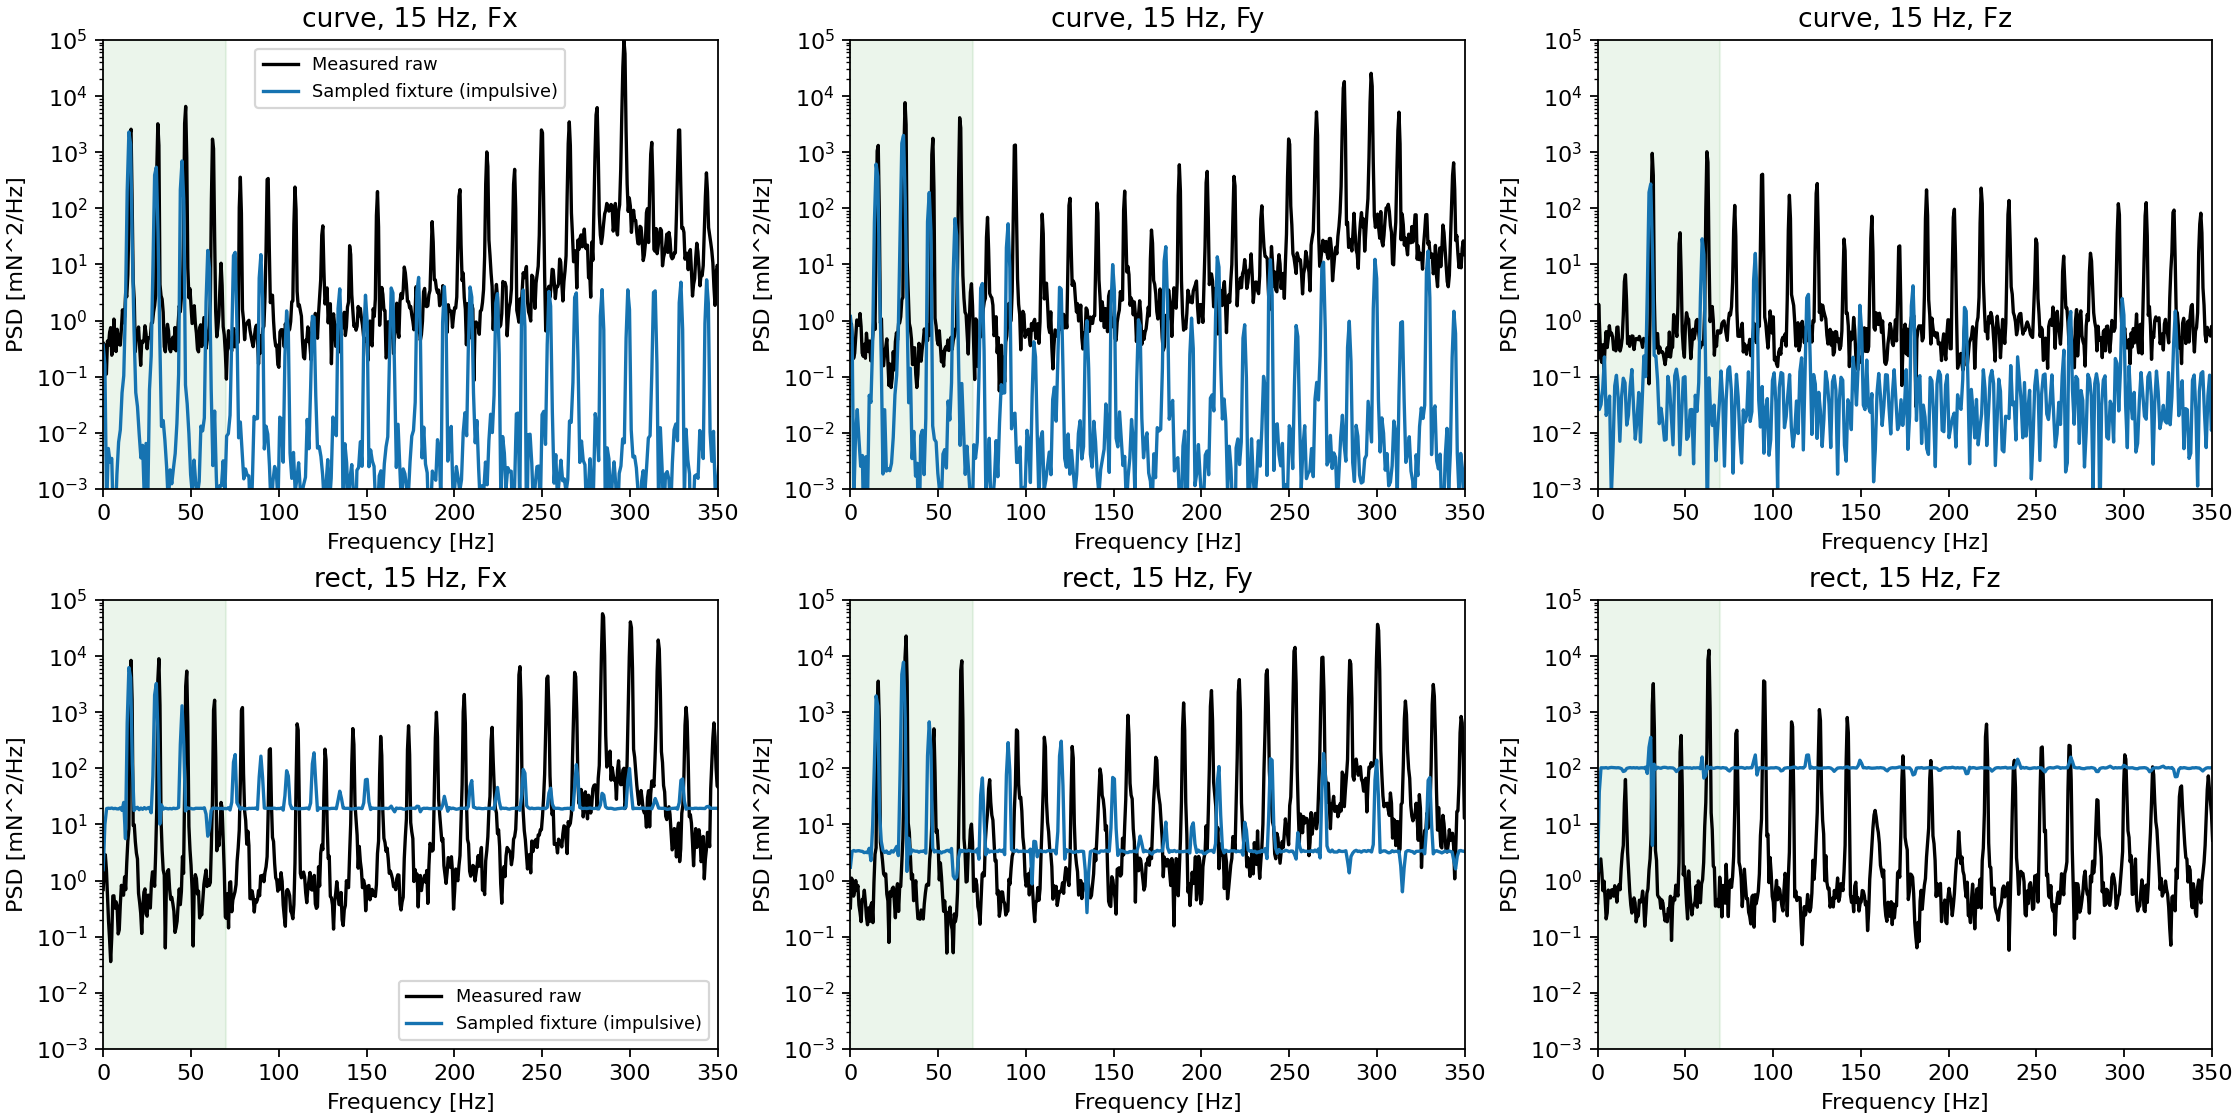

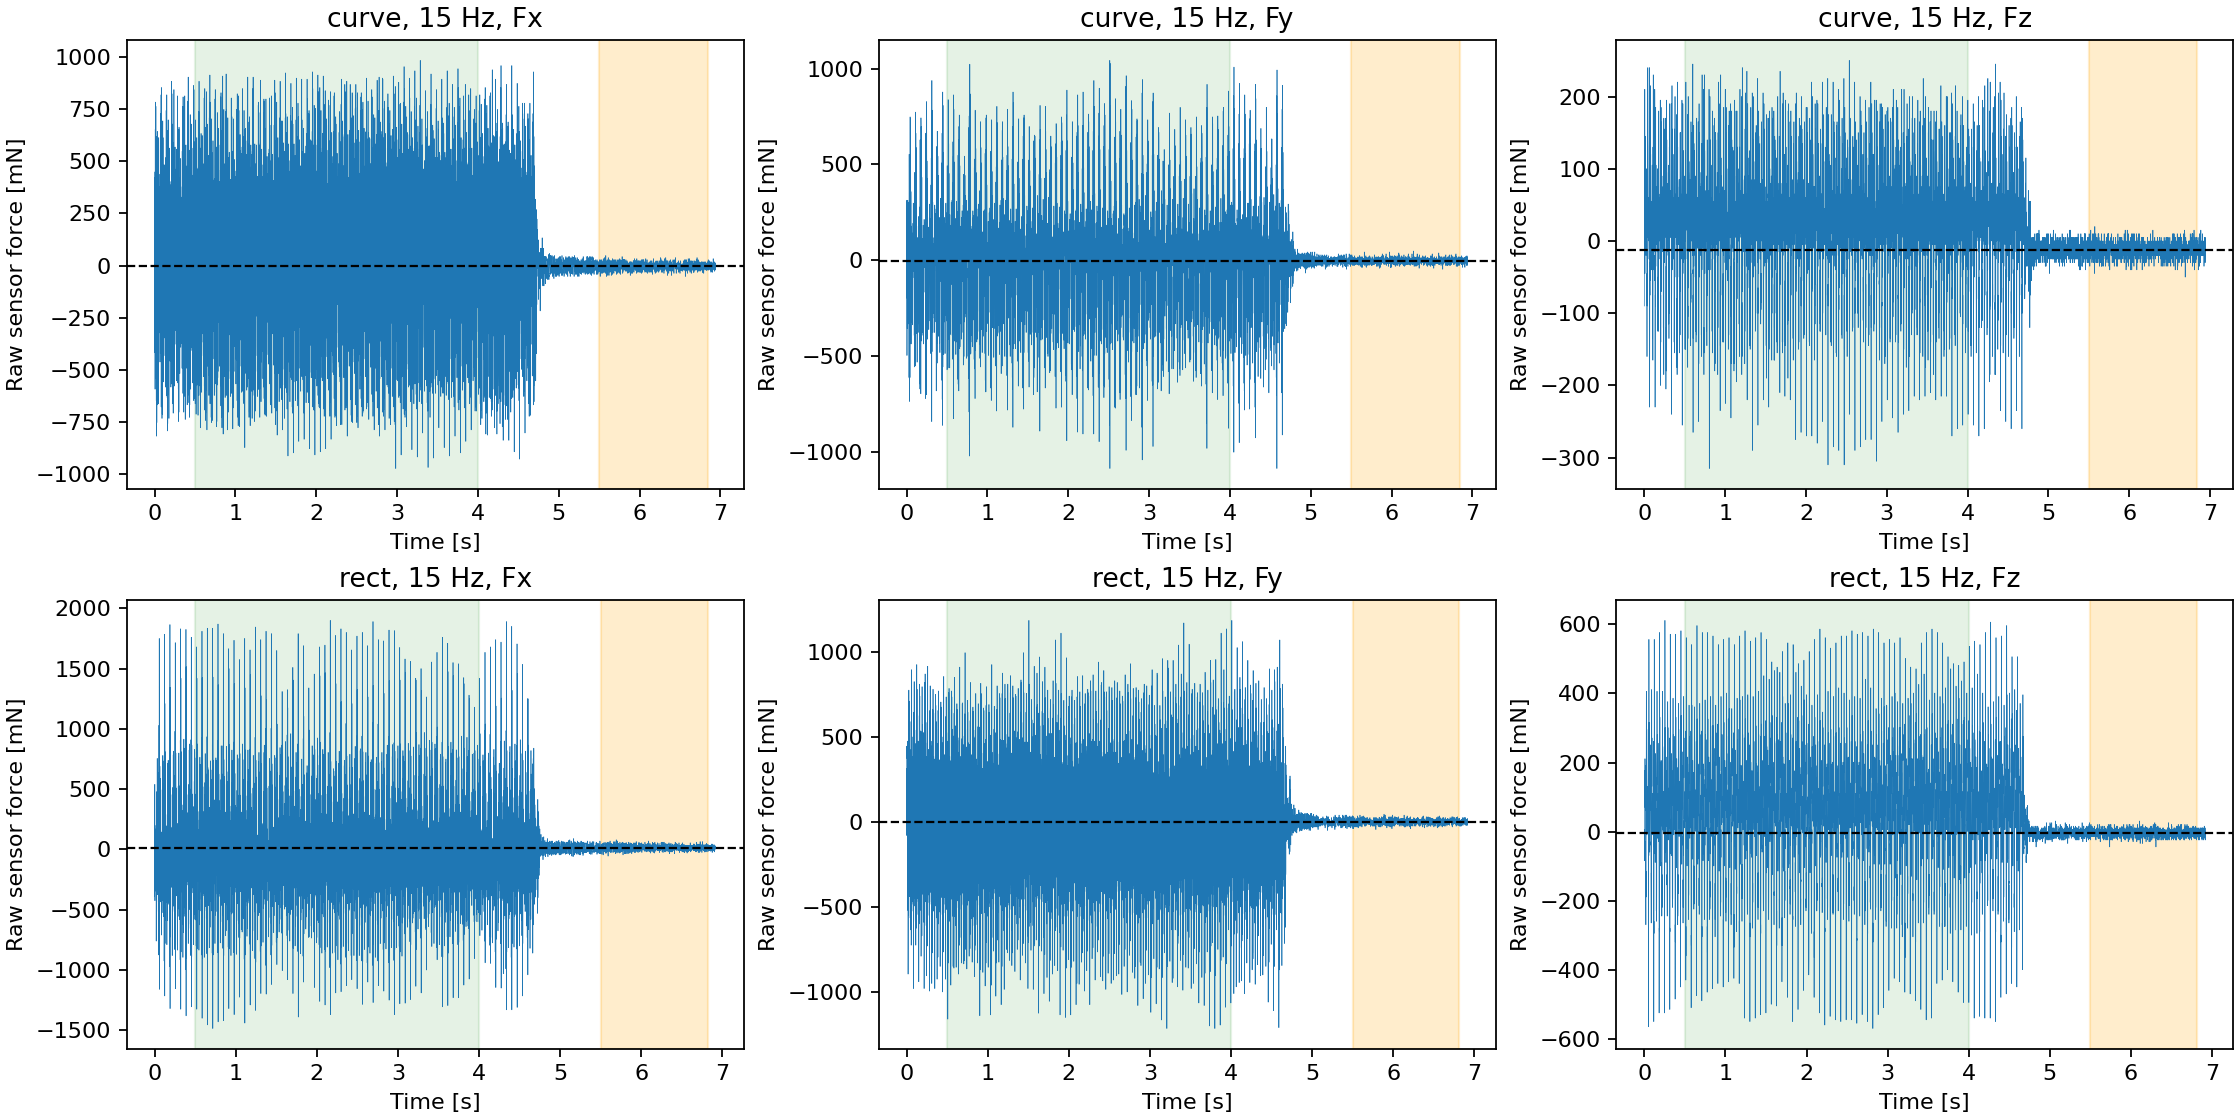

In [4]:
display(Image(filename=str(OUTPUT/'force_spectra.png')))
display(Image(filename=str(OUTPUT/'raw_windows.png')))

In [5]:
results=json.loads((OUTPUT/'momentum_summary.json').read_text())
assert len(results)==12
for r in results:
    assert abs(r['measured_wing_frequency_hz']-r['target_wing_frequency_hz']) < .01
    assert r['max_base_pose_error']==0 and not any(r['numerical_warnings'])
    np.testing.assert_allclose(r['feathering_limits_deg'],[-26.1,26.1],atol=1e-8)
    with np.load(OUTPUT/r['source']) as data:
        assert all(np.isfinite(data[k]).all() for k in data.files)
        assert 'momentum_x' in data
print('12 cases checked: frequency, fixed base, feathering limits, finite data and momentum.')
display(Markdown('## 解释与限制'+chr(10)*2+report.split('## 差距的解释与下一步证据')[1]))

12 cases checked: frequency, fixed base, feathering limits, finite data and momentum.


## 解释与限制


1. 已证实：矩形翼升力增幅比模型预测更大。15 Hz 档实测 rect/curve≈1.99，仿真≈1.55。
   两组实际频率略不同，比例只作该档位对比。面积与外展面积分布是模型输入，不能单凭总面积比例代替动力学运行。
2. 已证实：单纯绕 Z 轴改变坐标不能修复 Fz；现有匹配残差也不能仅归因于 X/Y 接反。
3. 尚不能区分：真实羽化波形、翼膜变形、翼架/膜质量与惯量、气动模型遗漏，以及实际运动/频率的差别。
   羽化限位相同不代表换向时间和相位相同；需要实测运动视频/角度才能验证此项，不能由力曲线反推出唯一原因。
4. 优先核对矩形翼总质量、翼膜在 STEP 上的边界、安装偏移，以及共同时间基准；再以运动数据约束模型。
   不建议凭一个翼形拟合统一力倍率后宣称两种翼均验证通过。

## 统计解释检查（11/11）
1. Simpson：分翼型/频率分别报告，未以混合回归替代分组结果。
2. 生态谬误：三次重复是统计单位，不推断单个采样点的独立性。
3. Berkson：所给记录全纳入，不按匹配好坏筛选。
4. Collider：未以拟合误差筛选/控制实验样本。
5. 基率：无诊断概率，不适用。
6. 均值回归：无极值筛选前后对照，不适用。
7. 幸存者偏差：36 次实测全保留，未删除不匹配的频率或翼型。
8. 多处寻找效应：无显著性检验；全部频率、轴和两种拟合口径均报告。
9. 分析路径自由度：基线、频带、质量、翼膜边界均明示；结论是探索性，存在未确认假设。
10. 相关与因果：残差不作为某个气动物理机制已被证实的依据。
11. 反向因果：不以力匹配反推出唯一的真实羽化运动或安装方向。

## 复现与文件
运行环境：Python / MuJoCo / NumPy / SciPy；STEP 准备另外需要 cadquery-ocp 与 trimesh。
Open CASCADE 的体积积分在未指定材料时给出几何体积；质量需要另乘密度，详见 [官方 BRepGProp 文档](https://occt3d.com/dev/doc/refman/html/class_b_rep_g_prop.html)。

```bash
python experiments/fixbase_curved_real/inspect_step.py
python experiments/fixbase_curved_real/rect_real_data.py
python experiments/fixbase_curved_real/rect_simulation.py --prepare --run
python experiments/fixbase_curved_real/rect_simulation.py --sensitivity
python experiments/fixbase_curved_real/rect_simulation.py --momentum
python experiments/fixbase_curved_real/rect_compare.py
python experiments/fixbase_curved_real/rect_report.py
```

`source_manifest.json` 记录 144 个原始 CSV 哈希；`geometry/model_assumptions.json` 记录几何、惯量假设与源文件哈希。
`momentum_summary.json` 指向最终 12 次运行；`simulation_summary.json` 保留初次运行；`sensitivity_summary.json` 为预先列出的三项敏感性。
每次运行保存六维气动力、六维支座动态载荷、运动角度、频率校准记录；最终运行增加总线动量。
力矩原点仍为 base_link；由于传感器原点/力臂未知，本次不将力矩旋转后冒充直接验证。
